In [88]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [89]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.ensemble import StackingClassifier


In [90]:
!pip install ucimlrepo

In [91]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
student_performance = fetch_ucirepo(id=320) 
  
# data (as pandas dataframes) 
X = student_performance.data.features 
y = student_performance.data.targets 
  
# metadata 
print(student_performance.metadata) 
  
# variable information 
print(student_performance.variables) 


{'uci_id': 320, 'name': 'Student Performance', 'repository_url': 'https://archive.ics.uci.edu/dataset/320/student+performance', 'data_url': 'https://archive.ics.uci.edu/static/public/320/data.csv', 'abstract': 'Predict student performance in secondary education (high school). ', 'area': 'Social Science', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 649, 'num_features': 30, 'feature_types': ['Integer'], 'demographics': ['Sex', 'Age', 'Other', 'Education Level', 'Occupation'], 'target_col': ['G1', 'G2', 'G3'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2008, 'last_updated': 'Fri Jan 05 2024', 'dataset_doi': '10.24432/C5TG7T', 'creators': ['Paulo Cortez'], 'intro_paper': {'ID': 360, 'type': 'NATIVE', 'title': 'Using data mining to predict secondary school student performance', 'authors': 'P. Cortez, A. M. G. Silva', 'venue': 'Proceedings of 5th Annual Future Business Technolo

In [92]:
y = (student_performance.data.targets["G3"] >= 10).astype(int)

X.head(), y.head()

(  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
 0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
 1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
 2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
 3     GP   F   15       U     GT3       T     4     2   health  services  ...   
 4     GP   F   16       U     GT3       T     3     3    other     other  ...   
 
   higher internet  romantic  famrel  freetime goout Dalc Walc health absences  
 0    yes       no        no       4         3     4    1    1      3        4  
 1    yes      yes        no       5         3     3    1    1      3        2  
 2    yes      yes        no       4         3     2    2    3      3        6  
 3    yes      yes       yes       3         2     2    1    1      5        0  
 4    yes       no        no       4         3     2    1    2      5        0  
 
 [5 rows x 30 colu

 since G1 and G2 are basically part of G3 -> data leakage 

select the final grade column (G3) from the dataset <br>
check whether each student’s final grade is 10 or higher

In [93]:
print(X.shape)
print(X.dtypes)
X.head()


(649, 30)
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
dtype: object


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,yes,no,no,4,3,4,1,1,3,4
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,yes,no,5,3,3,1,1,3,2
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,yes,no,4,3,2,2,3,3,6
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,yes,3,2,2,1,1,5,0
4,GP,F,16,U,GT3,T,3,3,other,other,...,yes,no,no,4,3,2,1,2,5,0


In [94]:
X.isna().sum()
y.isna().sum()


0

In [95]:
y.value_counts(), y.value_counts(normalize=True)


(G3
 1    549
 0    100
 Name: count, dtype: int64,
 G3
 1    0.845917
 0    0.154083
 Name: proportion, dtype: float64)

1 (Pass) = 549 students  -> 84.6% <br>
0 (Fail) = 100 students  -> 15.4% <br>
strongly imbalanced classification problem

use: <br>
class_weight="balanced" for Logistic Regression, Decision Tree <br>
look at thresholds 


In [96]:
categorical_cols = [
    'school', 'sex', 'address', 'famsize', 'Pstatus',
    'Mjob', 'Fjob', 'reason', 'guardian',
    'schoolsup', 'famsup', 'paid', 'activities',
    'nursery', 'higher', 'internet', 'romantic'
]


In [97]:
numeric_cols = [
    'age', 'Medu', 'Fedu', 'traveltime', 'studytime',
    'failures', 'famrel', 'freetime', 'goout',
    'Dalc', 'Walc', 'health', 'absences'
]


In [98]:
for col in categorical_cols:
    print(f"{col:12}  →  {X[col].nunique()} categories  →  {X[col].unique().tolist()}")


school        →  2 categories  →  ['GP', 'MS']
sex           →  2 categories  →  ['F', 'M']
address       →  2 categories  →  ['U', 'R']
famsize       →  2 categories  →  ['GT3', 'LE3']
Pstatus       →  2 categories  →  ['A', 'T']
Mjob          →  5 categories  →  ['at_home', 'health', 'other', 'services', 'teacher']
Fjob          →  5 categories  →  ['teacher', 'other', 'services', 'health', 'at_home']
reason        →  4 categories  →  ['course', 'other', 'home', 'reputation']
guardian      →  3 categories  →  ['mother', 'father', 'other']
schoolsup     →  2 categories  →  ['yes', 'no']
famsup        →  2 categories  →  ['no', 'yes']
paid          →  2 categories  →  ['no', 'yes']
activities    →  2 categories  →  ['no', 'yes']
nursery       →  2 categories  →  ['yes', 'no']
higher        →  2 categories  →  ['yes', 'no']
internet      →  2 categories  →  ['no', 'yes']
romantic      →  2 categories  →  ['no', 'yes']


one hot encoding wont explode feature cound 

In [99]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          
)


one hot encoding with protection for unseen categories to an all zero which is fine here since we are  <br>


In [100]:
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",    
    sparse_output=False         
)


In [101]:
from sklearn.compose import ColumnTransformer

numeric_transformer = "passthrough"

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_transformer, categorical_cols),
        ("numeric", numeric_transformer, numeric_cols)
    ]
)


In [102]:
from sklearn.preprocessing import StandardScaler

numeric_transformer = StandardScaler()


scaling since we are also usig logistic regression 

In [103]:
preprocessor.fit(X_train)


ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['school', 'sex', 'address', 'famsize',
                                  'Pstatus', 'Mjob', 'Fjob', 'reason',
                                  'guardian', 'schoolsup', 'famsup', 'paid',
                                  'activities', 'nursery', 'higher', 'internet',
                                  'romantic']),
                                ('numeric', 'passthrough',
                                 ['age', 'Medu', 'Fedu', 'traveltime',
                                  'studytime', 'failures', 'famrel', 'freetime',
                                  'goout', 'Dalc', 'Walc', 'health',
                                  'absences'])])

In [104]:
X_train_pre = preprocessor.transform(X_train)
X_test_pre  = preprocessor.transform(X_test)


In [105]:
ohe = preprocessor.named_transformers_["categorical"]
cat_feature_names = ohe.get_feature_names_out(categorical_cols)

num_feature_names = numeric_cols

all_feature_names = list(cat_feature_names) + num_feature_names


In [106]:
import pandas as pd

X_train_pre_df = pd.DataFrame(X_train_pre, columns=all_feature_names)
X_test_pre_df  = pd.DataFrame(X_test_pre,  columns=all_feature_names)


In [107]:
X_train_pre_df.shape
X_train_pre_df.head()


,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,Pstatus_T,...,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences
0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,...,1.0,3.0,0.0,5.0,3.0,3.0,1.0,3.0,5.0,0.0
1,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,...,1.0,3.0,0.0,4.0,3.0,4.0,1.0,1.0,5.0,12.0
2,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,1.0,2.0,1.0,4.0,5.0,4.0,1.0,2.0,5.0,0.0
3,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,2.0,2.0,0.0,4.0,1.0,3.0,1.0,3.0,4.0,0.0
4,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,...,1.0,2.0,0.0,4.0,4.0,4.0,1.0,1.0,3.0,2.0


In [108]:
X_train_pre_df.describe()


,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,Pstatus_T,...,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences
count,519.000000,519.000000,519.000000,519.000000,519.000000,519.000000,519.000000,519.000000,519.000000,519.000000,...,519.000000,519.000000,519.000000,519.000000,519.000000,519.000000,519.000000,519.000000,519.000000,519.000000
mean,0.676301,0.323699,0.593449,0.406551,0.289017,0.710983,0.703276,0.296724,0.115607,0.884393,...,1.549133,1.940270,0.229287,3.907514,3.169557,3.173410,1.493256,2.277457,3.539499,3.601156
std,0.468338,0.468338,0.491664,0.491664,0.453743,0.453743,0.457255,0.457255,0.320061,0.320061,...,0.751443,0.839595,0.614677,0.974145,1.077211,1.184189,0.919256,1.297493,1.445897,4.581404
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000
50%,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,...,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,...,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,30.000000


In [109]:
X_train_pre_df[numeric_cols].describe().round(3)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences
count,519.000,519.000,519.000,519.000,519.00,519.000,519.000,519.000,519.000,519.000,519.000,519.000,519.000
mean,16.736,2.503,2.293,1.549,1.94,0.229,3.908,3.170,3.173,1.493,2.277,3.539,3.601
std,1.246,1.139,1.113,0.751,0.84,0.615,0.974,1.077,1.184,0.919,1.297,1.446,4.581
min,15.000,0.000,0.000,1.000,1.00,0.000,1.000,1.000,1.000,1.000,1.000,1.000,0.000
25%,16.000,2.000,1.000,1.000,1.00,0.000,4.000,3.000,2.000,1.000,1.000,2.000,0.000
50%,17.000,2.000,2.000,1.000,2.00,0.000,4.000,3.000,3.000,1.000,2.000,4.000,2.000
75%,18.000,4.000,3.000,2.000,2.00,0.000,5.000,4.000,4.000,2.000,3.000,5.000,6.000
max,22.000,4.000,4.000,4.000,4.00,3.000,5.000,5.000,5.000,5.000,5.000,5.000,30.000


In [110]:
X_train_pre_df.filter(like="school").head()


,school_GP,school_MS,schoolsup_no,schoolsup_yes
0,1.0,0.0,1.0,0.0
1,1.0,0.0,1.0,0.0
2,0.0,1.0,1.0,0.0
3,1.0,0.0,0.0,1.0
4,1.0,0.0,0.0,1.0


In [111]:
len(all_feature_names)


56

after pre-processing <br>
Categorical one-hot = 43 columns, total 56 columns <br>
statistics match original data <br>
-> successfull preprocessing 

## Baseline Models

### Logistic Regression

In [112]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logreg_model = Pipeline([
    ("preprocessing", preprocessor),
    ("clf", LogisticRegression(
        class_weight="balanced", 
        max_iter=500,
        solver="lbfgs",
        random_state=42
    ))
])
logreg_model.fit(X_train, y_train)
y_pred = logreg_model.predict(X_test)
y_prob = logreg_model.predict_proba(X_test)[:, 1]   
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)
cm        = confusion_matrix(y_test, y_pred)

print("Logistic Regression Results:")
print("----------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print("\nConfusion Matrix:")
print(cm)




Logistic Regression Results:
----------------------------
Accuracy : 0.6538
Precision: 0.8736
Recall   : 0.6909
F1 Score : 0.7716

Confusion Matrix:
[[ 9 11]
 [34 76]]


When the model predicts pass, it’s usually correct <br>
finds 69% of passing students <br>
accuracy lower, making sense regarding data imbalance <br>
tends to underpredict fail, again data imbalance 


In [113]:
import numpy as np

thresholds = np.arange(0.1, 0.9, 0.05)

for t in thresholds:
    preds = (y_prob >= t).astype(int)
    print(t, f1_score(y_test, preds))


0.1 0.8761061946902655
0.15000000000000002 0.8663594470046083
0.20000000000000004 0.8544600938967137
0.25000000000000006 0.8380952380952381
0.30000000000000004 0.8252427184466018
0.3500000000000001 0.8252427184466018
0.40000000000000013 0.8137254901960784
0.45000000000000007 0.7839195979899497
0.5000000000000001 0.7715736040609137
0.5500000000000002 0.7461139896373057
0.6000000000000002 0.7272727272727273
0.6500000000000001 0.7135135135135136
0.7000000000000002 0.6961325966850829
0.7500000000000002 0.6666666666666667
0.8000000000000002 0.611764705882353
0.8500000000000002 0.588957055214724


since the dataset is imbalances it makes sense to test out different thresholds: <br>
the threshold at 0.10 works best because model finds more correct pass students <br>


In [114]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

dt_model = Pipeline([
    ("preprocessing", preprocessor),
    ("clf", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=None,        
        random_state=42
    ))
])
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

accuracy_dt  = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt    = recall_score(y_test, y_pred_dt)
f1_dt        = f1_score(y_test, y_pred_dt)
cm_dt        = confusion_matrix(y_test, y_pred_dt)

print("Decision Tree Results:")
print("------------------------")
print(f"Accuracy : {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall   : {recall_dt:.4f}")
print(f"F1 Score : {f1_dt:.4f}")
print("\nConfusion Matrix:")
print(cm_dt)


Decision Tree Results:
------------------------
Accuracy : 0.7000
Precision: 0.8447
Recall   : 0.7909
F1 Score : 0.8169

Confusion Matrix:
[[ 4 16]
 [23 87]]


model is correct 70% of the time -> better than Logistic Regression <br>
when the tree predicts PASS, it is right 84% of the time <br>
when the tree predicts PASS, it is right 84% of the time again better than before <br>
F1 way better than for Logistic Regression 

# 3. Bagging Ensemble: Random Forest using sklearn.ensemble.BaggingClassifier

# 4. Boosting Ensemble: Gradient Boosting vs AdaBoost

In [131]:
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


## 4a. Gradient Boosting

In [129]:
gb_model = Pipeline([
    ("preprocessing", preprocessor),
    ("clf", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)

gb_acc = accuracy_score(y_test, y_pred_gb)
gb_prec = precision_score(y_test, y_pred_gb)
gb_rec = recall_score(y_test, y_pred_gb)
gb_f1 = f1_score(y_test, y_pred_gb)

## 4b. Adaboost

In [130]:
ad_model = Pipeline([
    ("preprocessing", preprocessor),
    ("clf", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1), 
        n_estimators=200,
        learning_rate=0.1,
        random_state=42
    ))
])

ad_model.fit(X_train, y_train)
y_pred_ad = ad_model.predict(X_test)

ad_acc = accuracy_score(y_test, y_pred_ad)
ad_prec = precision_score(y_test, y_pred_ad)
ad_rec = recall_score(y_test, y_pred_ad)
ad_f1 = f1_score(y_test, y_pred_ad)

## Comparison

In [127]:
results = pd.DataFrame({
    "Model": ["Gradient Boosting", "AdaBoost"],
    "Accuracy": [gb_acc, ad_acc],
    "Precision": [gb_prec, ad_prec],
    "Recall": [gb_rec, ad_rec],
    "F1 Score": [gb_f1, ad_f1],
    "RMSE": [gb_rmse, ad_rmse],
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Gradient Boosting,0.807692,0.869565,0.909091,0.888889
1,AdaBoost,0.800000,0.862069,0.909091,0.884956


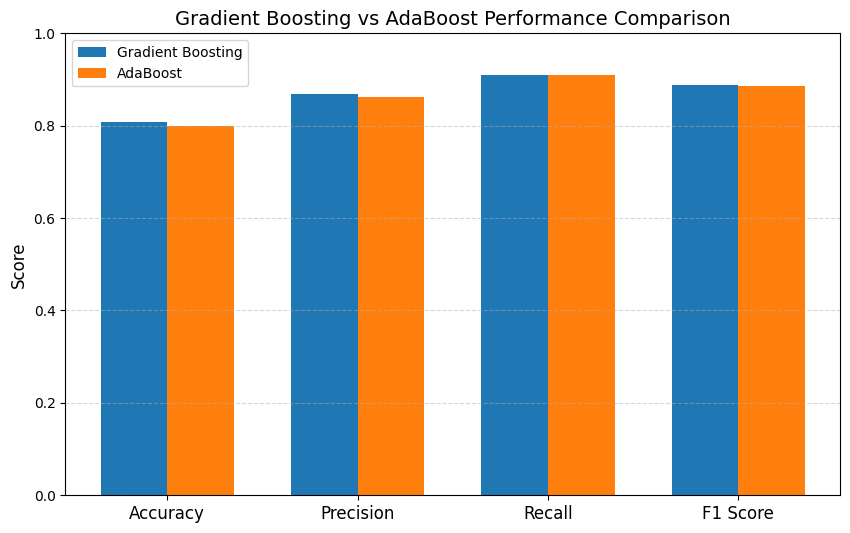

In [133]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]
gb_scores = [gb_acc, gb_prec, gb_rec, gb_f1]
ada_scores = [ad_acc, ad_prec, ad_rec, ad_f1]
x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, gb_scores, width, label="Gradient Boosting")
plt.bar(x + width/2, ada_scores, width, label="AdaBoost")

plt.xticks(x, metrics, fontsize=12)
plt.ylabel("Score", fontsize=12)
plt.title("Gradient Boosting vs AdaBoost Performance Comparison", fontsize=14)
plt.ylim(0, 1)

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

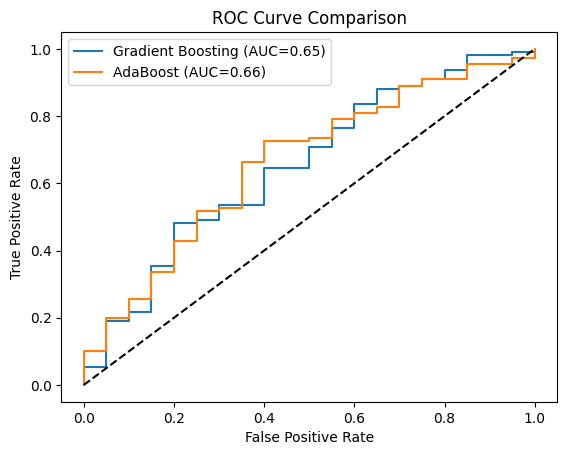

In [140]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Get class-1 probabilities
gb_probs = gb_model.predict_proba(X_test)[:, 1]
ad_probs = ad_model.predict_proba(X_test)[:, 1]

# FPR and TPR values
fpr_gb, tpr_gb, _ = roc_curve(y_test, gb_probs)
fpr_ad, tpr_ad, _ = roc_curve(y_test, ad_probs)

# AUC score
auc_gb = auc(fpr_gb, tpr_gb)
auc_ad = auc(fpr_ad, tpr_ad)

# Plot
plt.plot(fpr_gb, tpr_gb, label=f"Gradient Boosting (AUC={auc_gb:.2f})")
plt.plot(fpr_ad, tpr_ad, label=f"AdaBoost (AUC={auc_ad:.2f})")
plt.plot([0,1], [0,1], 'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()


- Both models performed well with Accuracy around 0.80 and F1 ≈ 0.88.
- Gradient Boosting slightly outperformed AdaBoost in Accuracy, Precision and F1.
- Recall was identical for both models (0.9091), showing strong ability to detect positive cases.
- AdaBoost was a bit more sensitive to mistakes, leading to slightly lower precision.
- Overall, Gradient Boosting generalized better, but both improved over the baseline Decision Tree.

# stacking ensemble with Logistic Regression + Random Forest + Gradient Boosting

In [120]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

estimators = [
    ('lr', LogisticRegression(class_weight='balanced', max_iter=500, random_state=42)),
    ('rf', RandomForestClassifier(class_weight='balanced', random_state=42)),
    ('gb', GradientBoostingClassifier(random_state=42)),
]

stack_model = Pipeline([
    ("preprocessing", preprocessor),
    ("stack", StackingClassifier(
        estimators=estimators,
        final_estimator=LogisticRegression(max_iter=500, random_state=42),
        passthrough=False,      
        cv=5
    ))
])

stack_model.fit(X_train, y_train)
y_pred_stack = stack_model.predict(X_test)
y_prob_stack = stack_model.predict_proba(X_test)[:, 1]

accuracy_s  = accuracy_score(y_test, y_pred_stack)
precision_s = precision_score(y_test, y_pred_stack)
recall_s    = recall_score(y_test, y_pred_stack)
f1_s        = f1_score(y_test, y_pred_stack)
cm_s        = confusion_matrix(y_test, y_pred_stack)

print("STACKING Results:")
print("----------------------------")
print(f"Accuracy : {accuracy_s:.4f}")
print(f"Precision: {precision_s:.4f}")
print(f"Recall   : {recall_s:.4f}")
print(f"F1 Score : {f1_s:.4f}")
print("\nConfusion Matrix:")
print(cm_s)


STACKING Results:
----------------------------
Accuracy : 0.7923
Precision: 0.8547
Recall   : 0.9091
F1 Score : 0.8811

Confusion Matrix:
[[  3  17]
 [ 10 100]]


- model identifies 90.9% of PASS students correctly
- when model predicts PASS, it is correct 85% of the time
- strong balance of precision and recall
- accuracy = 0.7923 is impressive given heavy class imbalance

Logistic Regression : sees simple patterns <br>
Random Forest : good at capturing complicated rule combinations <br>
Gradient Boosting : good at finding tough borderline cases like students almost passing 

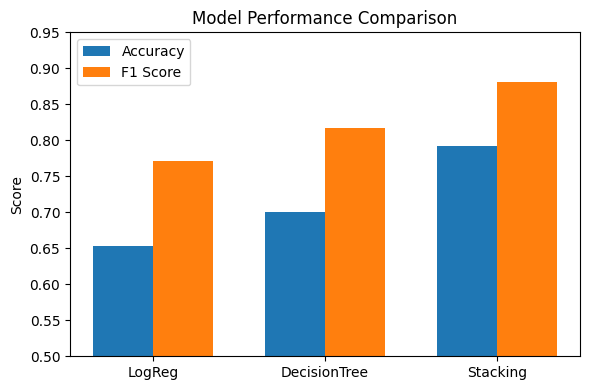

In [121]:
import matplotlib.pyplot as plt
import numpy as np

model_names = ["LogReg", "DecisionTree", "Stacking"]
accuracies = [0.6538, 0.7000, 0.7923]
f1_scores  = [0.7716, 0.8169, 0.8811]

x = np.arange(len(model_names))
width = 0.35

plt.figure(figsize=(6,4))
plt.bar(x - width/2, accuracies, width, label="Accuracy")
plt.bar(x + width/2, f1_scores, width, label="F1 Score")
plt.xticks(x, model_names)
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.ylim(0.5, 0.95)
plt.legend()
plt.tight_layout()
plt.show()


In [122]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline

base_models = {
    "LogReg": LogisticRegression(class_weight="balanced", max_iter=500, random_state=42),
    "RandomForest": RandomForestClassifier(class_weight="balanced", random_state=42),
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
}

for name, clf in base_models.items():
    pipe = Pipeline([
        ("preprocessing", preprocessor),
        ("clf", clf)
    ])
    scores = cross_val_score(pipe, X, y, cv=5, scoring="f1")
    print(f"{name}: mean F1={scores.mean():.4f} ± {scores.std():.4f}")


LogReg: mean F1=0.7541 ± 0.2361
RandomForest: mean F1=0.8924 ± 0.0434
GradientBoosting: mean F1=0.8739 ± 0.0706


In [123]:
import numpy as np
import pandas as pd

stack_clf = stack_model.named_steps["stack"]
meta_lr = stack_clf.final_estimator_

n_features_per_est = []
for est in stack_clf.estimators_:
    n_features_per_est.append(2)

coef = meta_lr.coef_.ravel()

feature_blocks = {}
start = 0
for name, n_feat in zip(["lr", "rf", "gb"], n_features_per_est):
    end = start + n_feat
    block_coef = coef[start:end]
    feature_blocks[name] = np.sum(np.abs(block_coef))
    start = end

contrib_df = pd.DataFrame.from_dict(feature_blocks, orient="index", columns=["abs_coef_sum"])
contrib_df["relative_importance"] = contrib_df["abs_coef_sum"] / contrib_df["abs_coef_sum"].sum()
print(contrib_df.sort_values("relative_importance", ascending=False))


    abs_coef_sum  relative_importance
lr      3.714525             0.682779
rf      1.725782             0.317221
gb      0.000000             0.000000


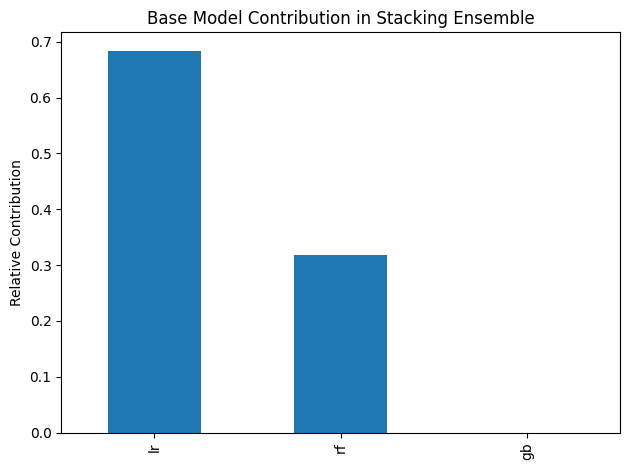

In [124]:
import matplotlib.pyplot as plt

contrib_df["relative_importance"].plot(kind="bar")
plt.ylabel("Relative Contribution")
plt.title("Base Model Contribution in Stacking Ensemble")
plt.tight_layout()
plt.show()


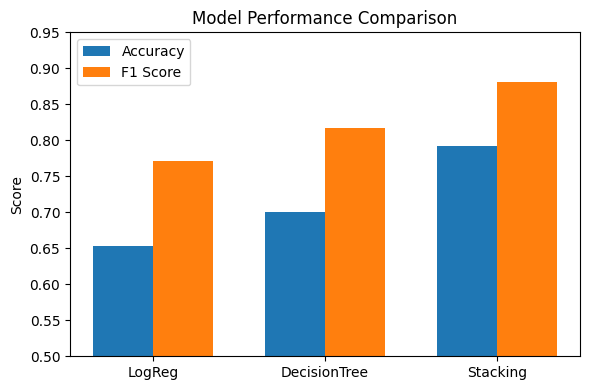

LogReg 0.7602234557231593 0.22700005164547724
RandomForest 0.8923809247246701 0.043439793340796895
GradientBoosting 0.8739487758313904 0.07060039005734145
    abs_coef_sum  relative_importance
lr      3.734359             0.685435
rf      1.713797             0.314565
gb      0.000000             0.000000


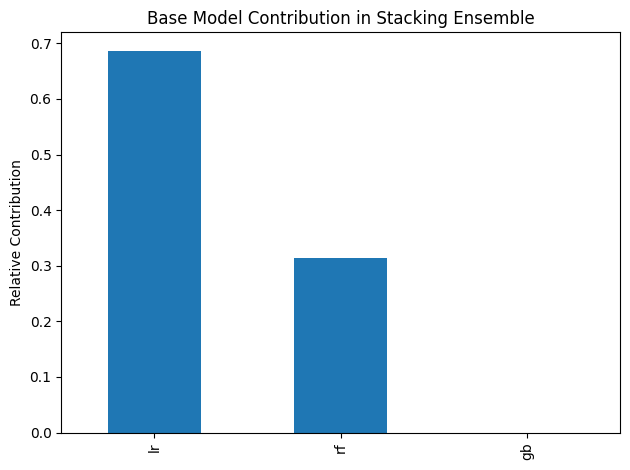

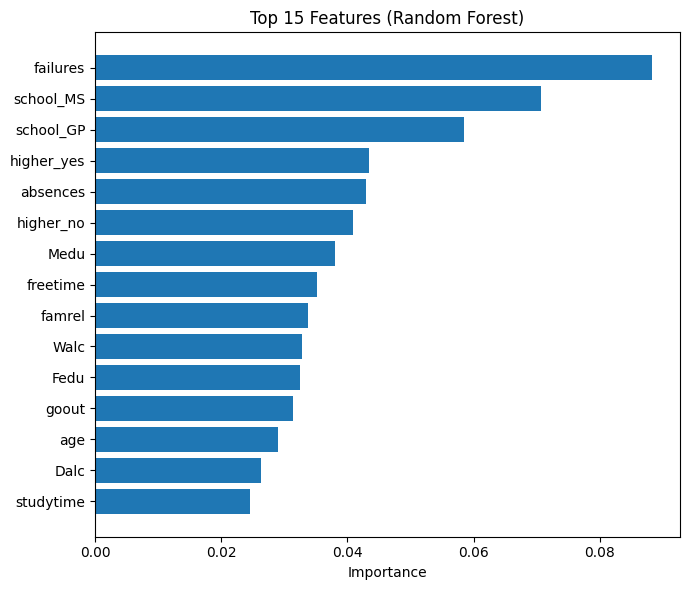

[[98  0]
 [ 0 32]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        98
           1       1.00      1.00      1.00        32

    accuracy                           1.00       130
   macro avg       1.00      1.00      1.00       130
weighted avg       1.00      1.00      1.00       130



In [125]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

student_performance = fetch_ucirepo(id=320)
X = student_performance.data.features
y = (student_performance.data.targets["G3"] >= 10).astype(int)

categorical_cols = [
    'school','sex','address','famsize','Pstatus','Mjob','Fjob','reason','guardian',
    'schoolsup','famsup','paid','activities','nursery','higher','internet','romantic'
]
numeric_cols = [
    'age','Medu','Fedu','traveltime','studytime','failures','famrel','freetime','goout',
    'Dalc','Walc','health','absences'
]

categorical_transformer = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
numeric_transformer = StandardScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_transformer, categorical_cols),
        ("numeric", numeric_transformer, numeric_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

logreg_model = Pipeline([
    ("preprocessing", preprocessor),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=500, solver="lbfgs",
                               random_state=42))
])
logreg_model.fit(X_train, y_train)
y_pred = logreg_model.predict(X_test)
y_prob = logreg_model.predict_proba(X_test)[:, 1]
accuracy_logreg = accuracy_score(y_test, y_pred)
precision_logreg = precision_score(y_test, y_pred)
recall_logreg = recall_score(y_test, y_pred)
f1_logreg = f1_score(y_test, y_pred)
cm_logreg = confusion_matrix(y_test, y_pred)

from sklearn.tree import DecisionTreeClassifier
dt_model = Pipeline([
    ("preprocessing", preprocessor),
    ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=42))
])
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
cm_dt = confusion_matrix(y_test, y_pred_dt)

estimators = [
    ('lr', LogisticRegression(class_weight='balanced', max_iter=500, random_state=42)),
    ('rf', RandomForestClassifier(class_weight='balanced', random_state=42)),
    ('gb', GradientBoostingClassifier(random_state=42)),
]

stack_model = Pipeline([
    ("preprocessing", preprocessor),
    ("stack", StackingClassifier(
        estimators=estimators,
        final_estimator=LogisticRegression(max_iter=500, random_state=42),
        passthrough=False,
        cv=5
    ))
])
stack_model.fit(X_train, y_train)
y_pred_stack = stack_model.predict(X_test)
y_prob_stack = stack_model.predict_proba(X_test)[:, 1]
accuracy_s = accuracy_score(y_test, y_pred_stack)
precision_s = precision_score(y_test, y_pred_stack)
recall_s = recall_score(y_test, y_pred_stack)
f1_s = f1_score(y_test, y_pred_stack)
cm_s = confusion_matrix(y_test, y_pred_stack)

model_names = ["LogReg", "DecisionTree", "Stacking"]
accuracies = [accuracy_logreg, accuracy_dt, accuracy_s]
f1_scores = [f1_logreg, f1_dt, f1_s]
x = np.arange(len(model_names))
width = 0.35
plt.figure(figsize=(6,4))
plt.bar(x - width/2, accuracies, width, label="Accuracy")
plt.bar(x + width/2, f1_scores, width, label="F1 Score")
plt.xticks(x, model_names)
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.ylim(0.5, 0.95)
plt.legend()
plt.tight_layout()
plt.show()

base_models = {
    "LogReg": LogisticRegression(class_weight="balanced", max_iter=500, random_state=42),
    "RandomForest": RandomForestClassifier(class_weight="balanced", random_state=42),
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
}

for name, clf in base_models.items():
    pipe = Pipeline([
        ("preprocessing", preprocessor),
        ("clf", clf)
    ])
    scores = cross_val_score(pipe, X, y, cv=5, scoring="f1")
    print(name, scores.mean(), scores.std())

stack_clf = stack_model.named_steps["stack"]
meta_lr = stack_clf.final_estimator_
n_features_per_est = [2, 2, 2]
coef = meta_lr.coef_.ravel()
feature_blocks = {}
start = 0
for name, n_feat in zip(["lr","rf","gb"], n_features_per_est):
    end = start + n_feat
    block_coef = coef[start:end]
    feature_blocks[name] = np.sum(np.abs(block_coef))
    start = end

contrib_df = pd.DataFrame.from_dict(feature_blocks, orient="index", columns=["abs_coef_sum"])
contrib_df["relative_importance"] = contrib_df["abs_coef_sum"] / contrib_df["abs_coef_sum"].sum()
print(contrib_df)

contrib_df["relative_importance"].plot(kind="bar")
plt.ylabel("Relative Contribution")
plt.title("Base Model Contribution in Stacking Ensemble")
plt.tight_layout()
plt.show()

rf_pipe = Pipeline([
    ("preprocessing", preprocessor),
    ("rf", RandomForestClassifier(class_weight="balanced", n_estimators=300, random_state=42))
])
rf_pipe.fit(X_train, y_train)
rf = rf_pipe.named_steps["rf"]
ohe = rf_pipe.named_steps["preprocessing"].named_transformers_["categorical"]
cat_feature_names = ohe.get_feature_names_out(categorical_cols)
num_feature_names = np.array(numeric_cols)
all_feature_names = np.concatenate([cat_feature_names, num_feature_names])
importances = rf.feature_importances_
feat_imp = pd.DataFrame({"feature": all_feature_names, "importance": importances})
feat_imp = feat_imp.sort_values("importance", ascending=False)
top_k = 15
top_feat = feat_imp.head(top_k).iloc[::-1]
plt.figure(figsize=(7,6))
plt.barh(top_feat["feature"], top_feat["importance"])
plt.xlabel("Importance")
plt.title("Top 15 Features (Random Forest)")
plt.tight_layout()
plt.show()

df = student_performance.data.features.copy()
df["G3"] = student_performance.data.targets["G3"]
df["dropout"] = (
    (df["absences"] >= 10) |
    (df["failures"] >= 1) |
    (df["G3"] < 8)
).astype(int)

X_dropout = df[categorical_cols + numeric_cols]
y_dropout = df["dropout"]

X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_dropout, y_dropout, test_size=0.2, random_state=42, stratify=y_dropout
)

estimators_dropout = [
    ('lr', LogisticRegression(class_weight='balanced', max_iter=500, random_state=42)),
    ('rf', RandomForestClassifier(class_weight='balanced', random_state=42)),
    ('gb', GradientBoostingClassifier(random_state=42)),
]

stack_dropout = Pipeline([
    ("preprocessing", preprocessor),
    ("stack", StackingClassifier(
        estimators=estimators_dropout,
        final_estimator=LogisticRegression(max_iter=500, class_weight="balanced"),
        cv=5
    ))
])

stack_dropout.fit(X_train_d, y_train_d)
y_prob_d = stack_dropout.predict_proba(X_test_d)[:, 1]
y_pred_d = stack_dropout.predict(X_test_d)

print(confusion_matrix(y_test_d, y_pred_d))
print(classification_report(y_test_d, y_pred_d))


Creating a dropout label using common dropout risk indicators: many absences, at least one past failure, very low final grade
1 -> high dropout risk <br>
0 -> low dropout risk <br>
keep data prep pipeline same <br>
reuse same stacked model, just trained on different target <br>
